In [1]:
 # Final charts
# Reads: ../data/clean_joined.csv 

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
# loading the joined table
df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")


In [4]:
# making a folder for the finished charts, so I can use them in my slides and article
os.makedirs("../charts", exist_ok=True)


In [5]:
def save(name):
    # I save the chart on my computer as a PNG picture
    plt.savefig(f"../charts/{name}.png", dpi=150, bbox_inches="tight")

# the dollar amounts I want to show on the income axis (the chart uses the log of income underneath)
dollar_ticks = [1000, 3000, 10000, 30000, 100000]
dollar_labels = ["1,000", "3,000", "10,000", "30,000", "100,000"]

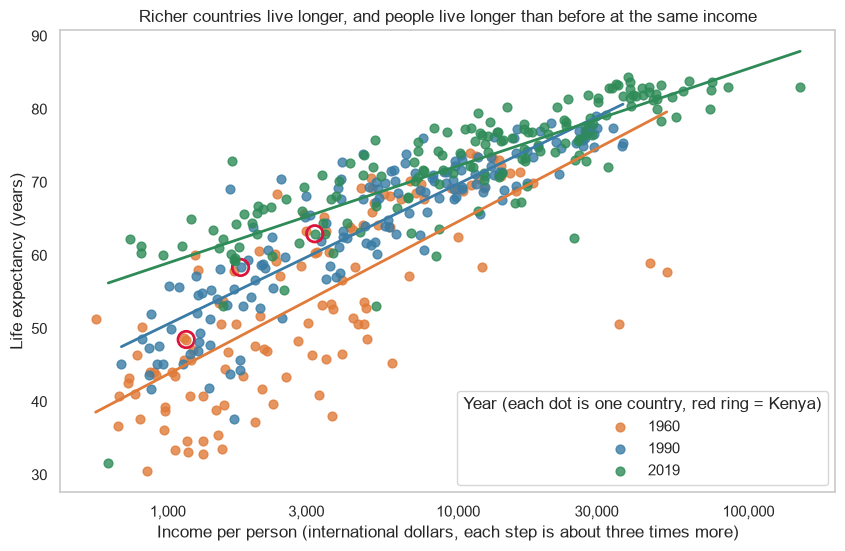

In [6]:
# Chart 1: richer countries live longer, in every year I looked at
years = [1960, 1990, 2019]
colors = ["#e07b39", "#3a7ca5", "#2e8b57"]

plt.figure(figsize=(10, 6))
for yr, col in zip(years, colors):
    d = df[df["Year"] == yr]
    # one dot per country
    plt.scatter(d["log_gdp"], d["life_exp"], s=40, color=col, alpha=0.8, label=f"{yr}")
    # a trend line for the year
    slope, intercept = np.polyfit(d["log_gdp"], d["life_exp"], 1)
    x = np.linspace(d["log_gdp"].min(), d["log_gdp"].max(), 100)
    plt.plot(x, slope * x + intercept, color=col, linewidth=2)
    # a red ring around Kenya
    k = d[d["Entity"] == "Kenya"]
    plt.scatter(k["log_gdp"], k["life_exp"], s=140, facecolor="none", edgecolor="crimson", linewidth=2)

plt.xticks(np.log(dollar_ticks), dollar_labels)
plt.title("Richer countries live longer, and people live longer than before at the same income", fontsize=12)
plt.xlabel("Income per person (international dollars, each step is about three times more)")
plt.ylabel("Life expectancy (years)")
plt.legend(title="Year (each dot is one country, red ring = Kenya)", loc="lower right")
plt.grid(False)
save("chart1_wealth_and_life_expectancy")
plt.show()

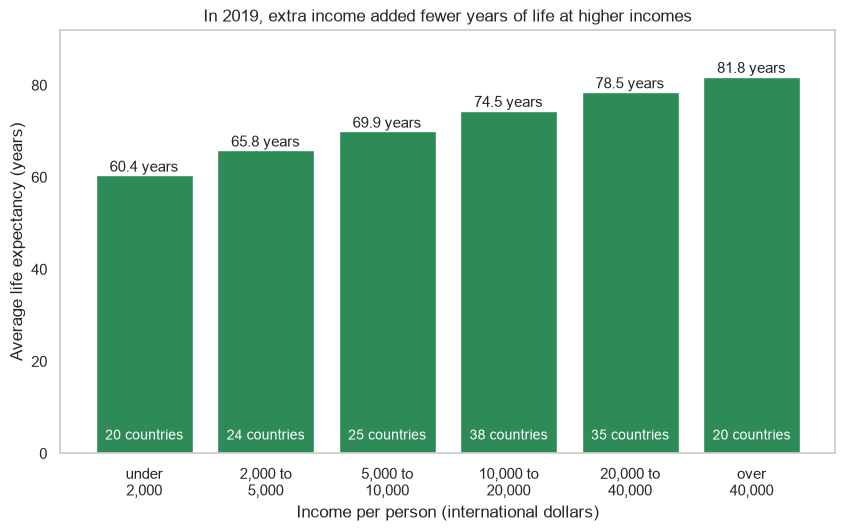

In [7]:
# Chart 2: each extra step up in income adds fewer years of life
one_year = df[df["Year"] == 2019]
bands = pd.cut(one_year["gdp_pc"], [0, 2000, 5000, 10000, 20000, 40000, 1e9],
               labels=["under\n2,000", "2,000 to\n5,000", "5,000 to\n10,000", "10,000 to\n20,000", "20,000 to\n40,000", "over\n40,000"])
band_table = one_year.groupby(bands, observed=True)["life_exp"].agg(["count", "mean"])

plt.figure(figsize=(10, 5.5))
bars = plt.bar(band_table.index.astype(str), band_table["mean"], color="#2e8b57")
for bar, (n, avg) in zip(bars, zip(band_table["count"], band_table["mean"])):
    plt.text(bar.get_x() + bar.get_width() / 2, avg + 0.8, f"{avg:.1f} years", ha="center", fontsize=11)
    plt.text(bar.get_x() + bar.get_width() / 2, 3, f"{n} countries", ha="center", color="white", fontsize=10)

plt.ylim(0, 92)
plt.title("In 2019, extra income added fewer years of life at higher incomes", fontsize=12)
plt.xlabel("Income per person (international dollars)")
plt.ylabel("Average life expectancy (years)")
plt.grid(False)
save("chart2_income_bands")
plt.show()

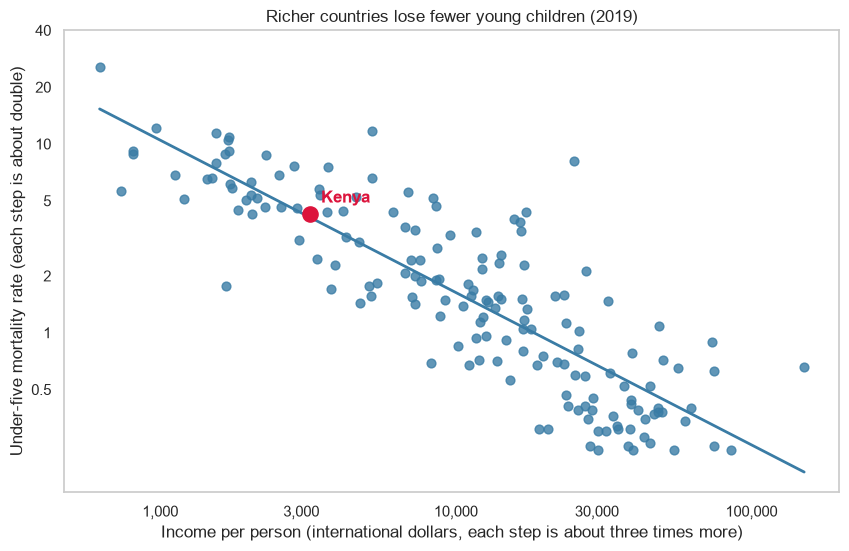

In [8]:
# Chart 3: richer countries lose fewer young children
one_year = df[df["Year"] == 2019]

plt.figure(figsize=(10, 6))
plt.scatter(one_year["log_gdp"], one_year["log_child_mort"], s=40, color="#3a7ca5", alpha=0.8)
slope, intercept = np.polyfit(one_year["log_gdp"], one_year["log_child_mort"], 1)
x = np.linspace(one_year["log_gdp"].min(), one_year["log_gdp"].max(), 100)
plt.plot(x, slope * x + intercept, color="#3a7ca5", linewidth=2)

# I highlight Kenya
k = one_year[one_year["Entity"] == "Kenya"]
plt.scatter(k["log_gdp"], k["log_child_mort"], s=120, color="crimson", zorder=3)
plt.annotate("Kenya", (k["log_gdp"].iloc[0], k["log_child_mort"].iloc[0]), textcoords="offset points",
             xytext=(8, 8), color="crimson", fontsize=12, fontweight="bold")

plt.xticks(np.log(dollar_ticks), dollar_labels)
plt.yticks(np.log([0.5, 1, 2, 5, 10, 20, 40]), ["0.5", "1", "2", "5", "10", "20", "40"])
plt.title("Richer countries lose fewer young children (2019)", fontsize=12)
plt.xlabel("Income per person (international dollars, each step is about three times more)")
plt.ylabel("Under-five mortality rate (each step is about double)")
plt.grid(False)
save("chart3_child_mortality")
plt.show()

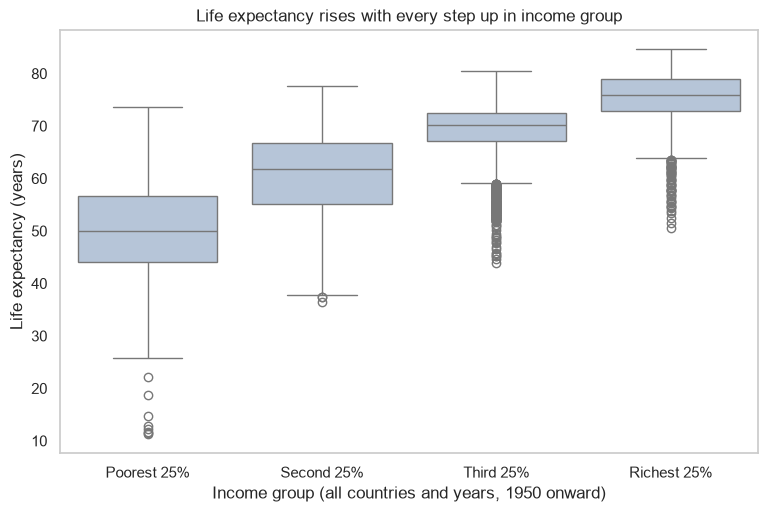

In [9]:
# Chart 4: life expectancy in the four income groups
order = ["Q1 poorest", "Q2", "Q3", "Q4 richest"]

plt.figure(figsize=(9, 5.5))
sns.boxplot(data=df, x="gdp_quartile", y="life_exp", order=order, color="lightsteelblue")
plt.xticks(range(4), ["Poorest 25%", "Second 25%", "Third 25%", "Richest 25%"])
plt.title("Life expectancy rises with every step up in income group", fontsize=12)
plt.xlabel("Income group (all countries and years, 1950 onward)")
plt.ylabel("Life expectancy (years)")
plt.grid(False)
save("chart4_income_groups")
plt.show()

In [10]:
import statsmodels.api as sm

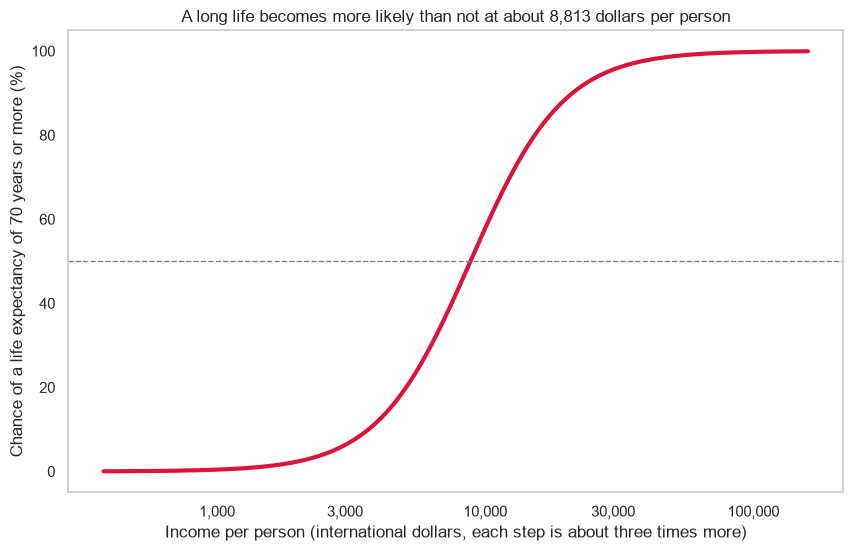

In [11]:
# Chart 5: the chance of living 70 years or more
df["long_life"] = (df["life_exp"] >= 70).astype(int)
model = sm.Logit(df["long_life"], sm.add_constant(df["log_gdp"])).fit(disp=False)

grid = pd.DataFrame({"log_gdp": np.linspace(df["log_gdp"].min(), df["log_gdp"].max(), 200)})
grid["chance"] = model.predict(sm.add_constant(grid["log_gdp"]))

plt.figure(figsize=(10, 6))
plt.plot(grid["log_gdp"], grid["chance"] * 100, color="crimson", linewidth=3)
plt.xticks(np.log(dollar_ticks), dollar_labels)
plt.axhline(50, color="gray", linestyle="--", linewidth=1)

# the income where the chance is exactly 50%
half_way = np.exp(-model.params["const"] / model.params["log_gdp"])
plt.title(f"A long life becomes more likely than not at about {half_way:,.0f} dollars per person", fontsize=12)
plt.xlabel("Income per person (international dollars, each step is about three times more)")
plt.ylabel("Chance of a life expectancy of 70 years or more (%)")
plt.grid(False)
save("chart5_chance_of_long_life")
plt.show()

Chart	

# 1	Richer countries live longer, and the lines for later years sit higher
# 2	Each step up in income band adds fewer years (60.4, 65.8, 69.9, 74.5, 78.5, 81.8)
# 3	Richer countries lose fewer young children
# 4	Each richer income group has a higher life expectancy
# 5	A long life becomes more likely than not at about 8,800 dollars
# 6	Average life expectancy was about 10 years higher from 2000 onward